# Leicester 2015/16: the signings, the spending, and the jump from 2014/15

Third part of the Leicester analysis (after `02_leicester_title` and `03_leicester_players`). Questions:

1. **Money:** how did Leicester's spending compare with the clubs they beat?
2. **Signings:** what did the summer 2015 signings contribute, compared with players in the same position and with the summer's big-money buys?
3. **Progression:** how much did Vardy, Mahrez and the team improve on 2014/15?

**Data sources.** All 2015/16 performance metrics come from StatsBomb event data (this repo). StatsBomb's free data has **no 2014/15 Premier League season**, so 2014/15 numbers, transfer fees and spending come from published sources, linked in each cell and in the Sources list at the end.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "2_27"
FIGS = ROOT / "reports" / "figures"

events = pd.read_parquet(DATA / "events.parquet")
players = pd.read_parquet(DATA / "player_season.parquet").set_index("player_id")
matches = pd.read_parquet(ROOT / "data" / "raw" / "2_27" / "matches.parquet")
LEI = "Leicester City"

BLUE, GREY, DARK, MUTED = "#1F5FAD", "#B4B2A9", "#3D3D3A", "#6B6A64"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

def subtitle(ax, text):
    ax.annotate(text, xy=(0, 1.01), xycoords="axes fraction", fontsize=9.5, color=MUTED)

def source(fig, text):
    fig.text(0.01, -0.02, text, fontsize=8, color="#8A8880")

## 1. Spending vs points

Gross summer 2015 transfer spend per club, as reported by [Sportskeeda](https://widgets.sportskeeda.com/football/how-much-all-20-premier-league-clubs-spend-2015-summer-transfer-window) (an independent source; fees are often undisclosed, so treat these as approximate). Points come from the StatsBomb match results.

In [2]:
spend = pd.Series({
    "Manchester City": 154.2, "Manchester United": 115.3, "Liverpool": 88.0, "Chelsea": 73.3,
    "Aston Villa": 53.4, "Tottenham Hotspur": 53.2, "Newcastle United": 47.8, "Southampton": 41.7,
    "Watford": 35.7, "West Ham United": 34.6, "West Bromwich Albion": 31.5, "Leicester City": 26.9,
    "Crystal Palace": 25.3, "AFC Bournemouth": 24.0, "Sunderland": 23.0, "Stoke City": 21.3,
    "Everton": 15.6, "Arsenal": 13.0, "Swansea City": 10.1, "Norwich City": 10.0,
}, name="summer_spend_gbp_m")

m = matches.assign(hs=matches.home_score.astype(int), aw=matches.away_score.astype(int))
pts = pd.concat([
    pd.DataFrame({"team": m.home_team, "pts": np.select([m.hs > m.aw, m.hs == m.aw], [3, 1], 0)}),
    pd.DataFrame({"team": m.away_team, "pts": np.select([m.aw > m.hs, m.aw == m.hs], [3, 1], 0)}),
]).groupby("team").pts.sum()
money = pd.DataFrame({"spend": spend, "points": pts})
money["spend_rank"] = money.spend.rank(ascending=False).astype(int)
money.sort_values("points", ascending=False)

,spend,points,spend_rank
Leicester City,26.9,81,12
Arsenal,13.0,71,18
Tottenham Hotspur,53.2,70,6
Manchester United,115.3,66,2
Manchester City,154.2,66,1
Southampton,41.7,63,8
West Ham United,34.6,62,10
Liverpool,88.0,60,3
Stoke City,21.3,51,16
Chelsea,73.3,50,4


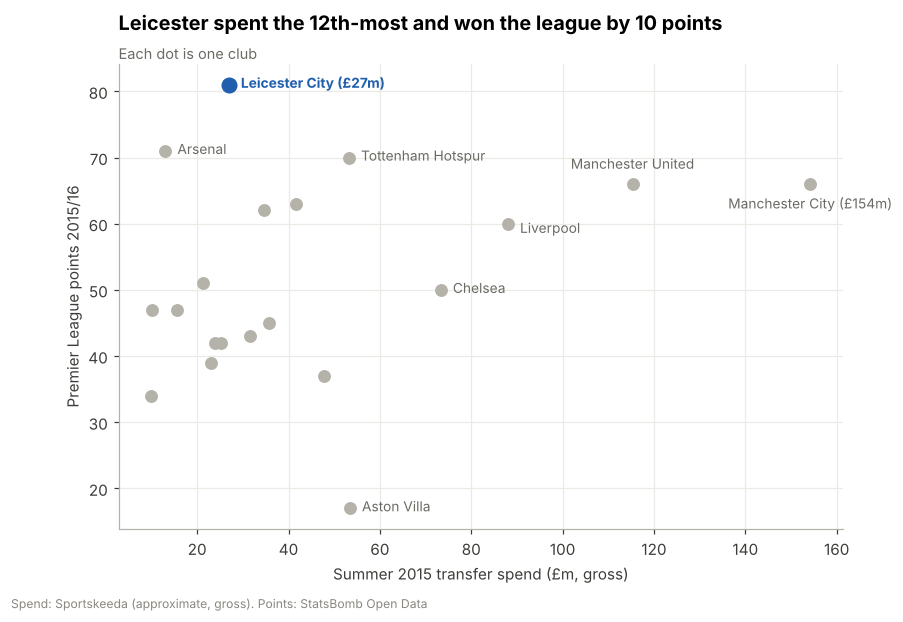

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
others = money.drop(LEI)
ax.scatter(others.spend, others.points, s=55, color=GREY, zorder=2)
ax.scatter(money.loc[LEI, "spend"], money.loc[LEI, "points"], s=90, color=BLUE, zorder=3)
labels = {LEI: (8, -2, "left"), "Manchester City": (0, -16, "center"), "Manchester United": (0, 10, "center"),
          "Arsenal": (8, -2, "left"), "Tottenham Hotspur": (8, -2, "left"), "Liverpool": (8, -6, "left"),
          "Chelsea": (8, -2, "left"), "Aston Villa": (8, -2, "left")}
for team, (dx, dy, ha) in labels.items():
    r = money.loc[team]
    ax.annotate(f"{team} (£{r.spend:.0f}m)" if team in [LEI, "Manchester City"] else team, (r.spend, r.points),
                xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=9,
                color=BLUE if team == LEI else MUTED, fontweight="bold" if team == LEI else "normal")
ax.set_xlabel("Summer 2015 transfer spend (£m, gross)")
ax.set_ylabel("Premier League points 2015/16")
ax.set_title("Leicester spent the 12th-most and won the league by 10 points", pad=22)
subtitle(ax, "Each dot is one club")
source(fig, "Spend: Sportskeeda (approximate, gross). Points: StatsBomb Open Data")
fig.savefig(FIGS / "10_spend_vs_points.png"); plt.show()

## 2. The summer 2015 signings

Fees from the [2015–16 Leicester City season article](https://en.wikipedia.org/wiki/2015%E2%80%9316_Leicester_City_F.C._season) (Wikipedia). Minutes and output come from StatsBomb.

In [4]:
fees = pd.DataFrame([
    ("Christian Fuchs", "Schalke 04", "Free", 0.0),
    ("Robert Huth", "Stoke City", "£3.0m", 3.0),
    ("Shinji Okazaki", "Mainz 05", "£7.0m", 7.0),
    ("N'Golo Kanté", "Caen", "£5.6m", 5.6),
    ("Yohan Benalouane", "Atalanta", "Undisclosed", np.nan),
    ("Gökhan İnler", "Napoli", "£3.0m", 3.0),
    ("Nathan Dyer", "Swansea City (loan)", "Loan", np.nan),
    ("Demarai Gray", "Birmingham City (Jan)", "£3.7m", 3.7),
    ("Daniel Amartey", "Copenhagen (Jan)", "£5.0m", 5.0),
], columns=["display_name", "from", "fee", "fee_m"])

shots = events[events.type == "Shot"].assign(xg=lambda d: d.shot_statsbomb_xg.astype(float),
                                             goal=lambda d: d.shot_outcome == "Goal")
f = lambda mask: events[mask].groupby("player_id").size()
tackles = (events.type == "Duel") & (events.duel_type == "Tackle")
stats = players.join(pd.DataFrame({
    "goals": shots.groupby("player_id").goal.sum(),
    "np_xg": shots[shots.shot_type != "Penalty"].groupby("player_id").xg.sum(),
    "assists": f(events.pass_goal_assist),
    "chances_created": f(events.pass_shot_assist | events.pass_goal_assist),
    "tackles": f(tackles), "interceptions": f(events.type == "Interception"),
    "ball_recoveries": f(events.type == "Ball Recovery"), "pressures": f(events.type == "Pressure"),
    "pressures_att_third": f((events.type == "Pressure") & (events.start_x >= 80)),
    "clearances": f(events.type == "Clearance"), "blocks": f(events.type == "Block"),
    "tackles_won": f(tackles & events.duel_outcome.isin(["Won", "Success In Play", "Success Out"])),
    "progressive_passes": f((events.type == "Pass") & events.pass_outcome.isna()
                            & ((events.pass_end_x - events.start_x) >= 10) & (events.pass_end_x >= 40)),
    "long_passes_completed": f((events.type == "Pass") & events.pass_outcome.isna()
                               & (events.pass_length.astype(float) >= 32)),
})).fillna(0)

signings = fees.merge(stats.reset_index(), on="display_name", how="left")
signings[["display_name", "from", "fee", "position_group", "minutes", "starts", "goals", "assists",
          "tackles", "interceptions", "blocks", "clearances", "pressures"]]

,display_name,from,fee,position_group,minutes,starts,goals,assists,tackles,interceptions,blocks,clearances,pressures
0,Christian Fuchs,Schalke 04,Free,Defender,2845,30,0.0,4.0,101.0,73.0,115.0,152.0,497.0
1,Robert Huth,Stoke City,£3.0m,Defender,3313,35,3.0,0.0,37.0,46.0,64.0,312.0,252.0
2,Shinji Okazaki,Mainz 05,£7.0m,Forward,2116,28,5.0,0.0,37.0,11.0,43.0,17.0,515.0
3,N'Golo Kanté,Caen,£5.6m,Midfielder,3179,33,1.0,3.0,164.0,110.0,114.0,77.0,906.0
4,Yohan Benalouane,Atalanta,Undisclosed,Defender,90,0,0.0,0.0,0.0,3.0,2.0,5.0,8.0
5,Gökhan İnler,Napoli,£3.0m,Midfielder,205,3,0.0,0.0,7.0,2.0,7.0,8.0,49.0
6,Nathan Dyer,Swansea City (loan),Loan,Midfielder,296,0,1.0,1.0,4.0,0.0,9.0,0.0,53.0
7,Demarai Gray,Birmingham City (Jan),£3.7m,Midfielder,228,1,0.0,1.0,4.0,6.0,8.0,3.0,53.0
8,Daniel Amartey,Copenhagen (Jan),£5.0m,Defender,120,1,0.0,0.0,1.0,3.0,2.0,4.0,16.0


Four signings became regulars, playing 2,100+ minutes each: **Kanté, Huth, Fuchs and Okazaki**, for about **£15.6m combined**.
The rest (İnler, Benalouane, Gray, Amartey, Dyer) played under 300 minutes each.

### How they ranked in their position

Percentile among players in the same position group with 900+ minutes (100 = best in the league). Metrics are per 90 minutes.

In [5]:
regulars = stats[(stats.minutes >= 900) & (stats.position_group != "Goalkeeper")]
metric_cols = ["goals", "np_xg", "assists", "chances_created", "tackles", "interceptions", "ball_recoveries",
               "pressures", "pressures_att_third", "clearances", "blocks", "tackles_won",
               "progressive_passes", "long_passes_completed"]
p90 = regulars[metric_cols].div(regulars.minutes, axis=0) * 90
pct = (p90.groupby(regulars.position_group).rank(pct=True) * 100).round(0)

def profile(name):
    pid = regulars.index[regulars.display_name == name][0]
    return pd.DataFrame({"per_90": p90.loc[pid].round(2), "percentile": pct.loc[pid]})

for name in ["N'Golo Kanté", "Robert Huth", "Christian Fuchs", "Shinji Okazaki"]:
    group = regulars.loc[regulars.display_name == name, "position_group"].iloc[0]
    print(f"\n{name} ({group}s, n={int((regulars.position_group == group).sum())})")
    print(profile(name).sort_values("percentile", ascending=False).head(6).to_string())


N'Golo Kanté (Midfielders, n=102)
                 per_90  percentile
tackles            4.64       100.0
interceptions      3.11       100.0
blocks             3.23       100.0
ball_recoveries    8.49       100.0
pressures         25.65        97.0
tackles_won        2.89        96.0

Robert Huth (Defenders, n=119)
               per_90  percentile
clearances       8.48        97.0
np_xg            0.07        86.0
goals            0.08        82.0
interceptions    1.25        45.0
blocks           1.74        32.0
assists          0.00        26.0

Christian Fuchs (Defenders, n=119)
                    per_90  percentile
blocks                3.64       100.0
chances_created       1.49        98.0
tackles_won           2.25        98.0
interceptions         2.31        96.0
progressive_passes   14.93        94.0
assists               0.13        93.0

Shinji Okazaki (Forwards, n=79)
                     per_90  percentile
pressures_att_third    7.40        92.0
pressures            

### Cheap signings vs the summer's big-money buys

Each Leicester signing is matched with a big-money summer 2015 signing who played a similar role. Fees for the big-money players come from [Sky Sports' list of the 10 most expensive deals of summer 2015](https://skysports.com/football/news/11096/9975549/the-10-most-expensive-deals-of-the-summer-transfer-window).

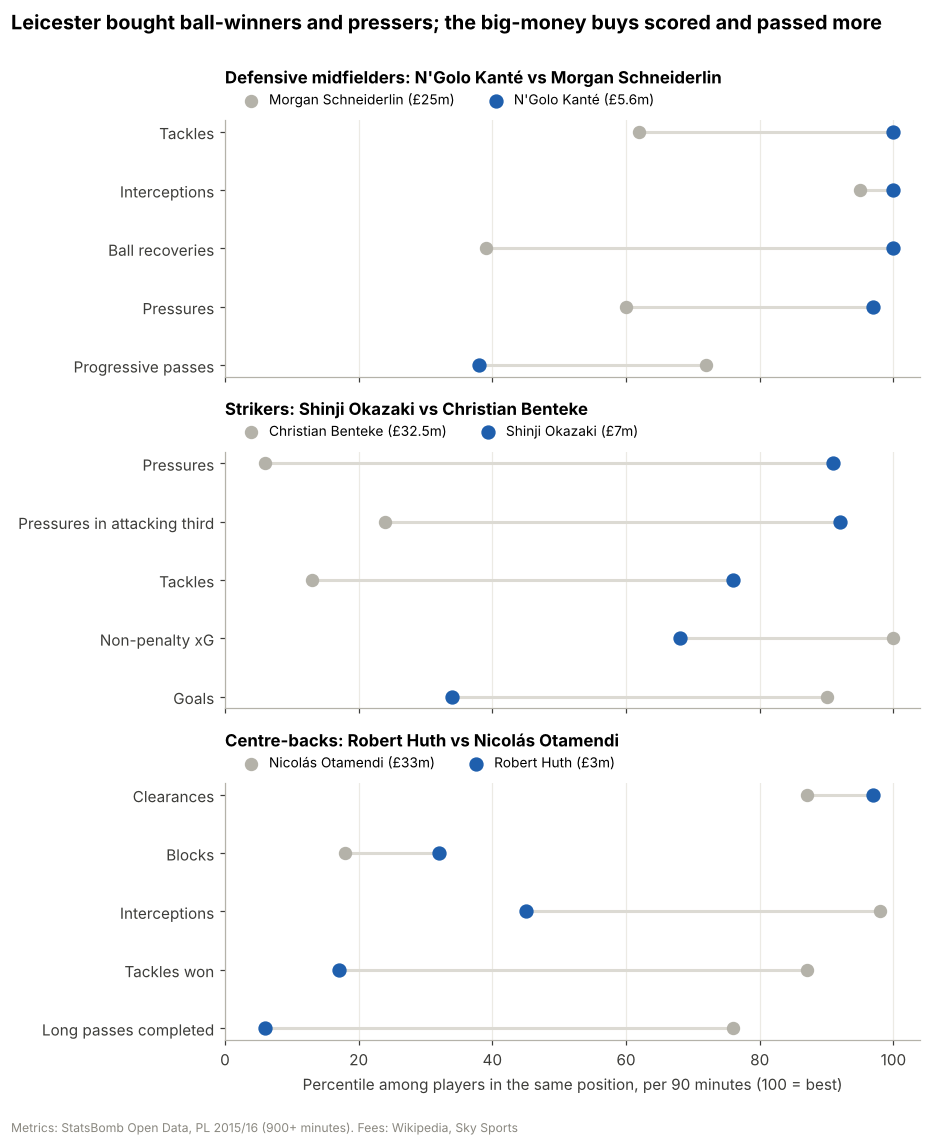

In [6]:
matchups = [
    ("N'Golo Kanté", "£5.6m", "Morgan Schneiderlin", "£25m", "Defensive midfielders",
     {"tackles": "Tackles", "interceptions": "Interceptions", "ball_recoveries": "Ball recoveries",
      "pressures": "Pressures", "progressive_passes": "Progressive passes"}),
    ("Shinji Okazaki", "£7m", "Christian Benteke", "£32.5m", "Strikers",
     {"pressures": "Pressures", "pressures_att_third": "Pressures in attacking third",
      "tackles": "Tackles", "np_xg": "Non-penalty xG", "goals": "Goals"}),
    ("Robert Huth", "£3m", "Nicolás Otamendi", "£33m", "Centre-backs",
     {"clearances": "Clearances", "blocks": "Blocks", "interceptions": "Interceptions",
      "tackles_won": "Tackles won", "long_passes_completed": "Long passes completed"}),
]
pid = lambda n: regulars.index[regulars.display_name == n][0]

fig, axes = plt.subplots(3, 1, figsize=(8.5, 10), sharex=True)
for ax, (lei, lei_fee, rival, rival_fee, role, mets) in zip(axes, matchups):
    rows = list(mets)[::-1]
    y = np.arange(len(rows))
    a = [pct.loc[pid(lei), m] for m in rows]
    b = [pct.loc[pid(rival), m] for m in rows]
    for i in y:
        ax.plot([a[i], b[i]], [i, i], color="#DCDAD3", lw=2, zorder=1)
    ax.scatter(b, y, s=60, color=GREY, zorder=2, label=f"{rival} ({rival_fee})")
    ax.scatter(a, y, s=70, color=BLUE, zorder=3, label=f"{lei} ({lei_fee})")
    ax.set_yticks(y, [mets[m] for m in rows])
    ax.set_xlim(0, 104)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{role}: {lei} vs {rival}", fontsize=11, pad=24)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9, handletextpad=0.3)
axes[-1].set_xlabel("Percentile among players in the same position, per 90 minutes (100 = best)")
fig.suptitle("Leicester bought ball-winners and pressers; the big-money buys scored and passed more",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
source(fig, "Metrics: StatsBomb Open Data, PL 2015/16 (900+ minutes). Fees: Wikipedia, Sky Sports")
fig.savefig(FIGS / "11_signings_vs_big_money.png"); plt.show()

In [7]:
big_money = pd.DataFrame([
    ("Kevin De Bruyne", "Manchester City", 54.5), ("Raheem Sterling", "Manchester City", 49.0),
    ("Anthony Martial", "Manchester United", 36.0), ("Nicolás Otamendi", "Manchester City", 33.0),
    ("Christian Benteke", "Liverpool", 32.5), ("Roberto Firmino", "Liverpool", 29.0),
    ("Memphis Depay", "Manchester United", 27.9), ("Morgan Schneiderlin", "Manchester United", 25.0),
    ("Pedro", "Chelsea", 21.4),
], columns=["display_name", "club", "fee_m"])
compare = pd.concat([
    big_money.assign(group="Top-10 summer deals"),
    fees[fees.display_name.isin(["N'Golo Kanté", "Robert Huth", "Christian Fuchs", "Shinji Okazaki"])]
        [["display_name", "fee_m"]].assign(club=LEI, group="Leicester regulars"),
]).merge(stats.reset_index()[["display_name", "minutes", "goals", "assists", "tackles", "interceptions"]], on="display_name")
compare["g_plus_a"] = compare.goals + compare.assists
compare["t_plus_i"] = compare.tackles + compare.interceptions
compare.groupby("group").agg(players=("display_name", "size"), total_fee_m=("fee_m", "sum"),
                             minutes=("minutes", "sum"), goals_plus_assists=("g_plus_a", "sum"),
                             tackles_plus_int=("t_plus_i", "sum")).astype({"minutes": int, "goals_plus_assists": int, "tackles_plus_int": int})

,players,total_fee_m,minutes,goals_plus_assists,tackles_plus_int
group,,,,,
Leicester regulars,4,15.6,11453,16,579
Top-10 summer deals,9,308.3,19287,80,639


## 3. 2014/15 → 2015/16: the jump

2014/15 figures are from Wikipedia's [2014–15 Leicester City season](https://en.wikipedia.org/wiki/2014%E2%80%9315_Leicester_City_F.C._season), [Jamie Vardy](https://en.wikipedia.org/wiki/Jamie_Vardy) and [Riyad Mahrez](https://en.wikipedia.org/wiki/Riyad_Mahrez) articles (league appearances and goals only; event data for 2014/15 isn't available).
2015/16 figures come from the StatsBomb data, and they agree with the same Wikipedia articles.

In [8]:
team_jump = pd.DataFrame({
    "2014/15": {"Position": 14, "Points": 41, "Goals for": 46, "Goals against": 55, "Wins": 11, "Losses": 19},
    "2015/16": {"Position": 1, "Points": int(pts[LEI]),
                "Goals for": int(m.loc[m.home_team == LEI, "hs"].sum() + m.loc[m.away_team == LEI, "aw"].sum()),
                "Goals against": int(m.loc[m.home_team == LEI, "aw"].sum() + m.loc[m.away_team == LEI, "hs"].sum()),
                "Wins": None, "Losses": None},
})
lei_rows = pd.concat([
    pd.DataFrame({"gf": m.loc[m.home_team == LEI, "hs"], "ga": m.loc[m.home_team == LEI, "aw"]}),
    pd.DataFrame({"gf": m.loc[m.away_team == LEI, "aw"], "ga": m.loc[m.away_team == LEI, "hs"]}),
])
team_jump.loc["Wins", "2015/16"] = int((lei_rows.gf > lei_rows.ga).sum())
team_jump.loc["Losses", "2015/16"] = int((lei_rows.gf < lei_rows.ga).sum())
team_jump = team_jump.astype(int)
team_jump["Change"] = team_jump["2015/16"] - team_jump["2014/15"]
team_jump

,2014/15,2015/16,Change
Position,14,1,-13
Points,41,81,40
Goals for,46,68,22
Goals against,55,36,-19
Wins,11,23,12
Losses,19,3,-16


**The run started in 2014/15.** Leicester were bottom of the table from late November 2014 to mid-April 2015, then won 7 of their last 9 matches (W7 D1 L1, 22 points) to survive.
Combined with 2015/16, that's **103 points from 47 league matches (2.19 per match)**, title-winning form over more than a full season.

In [9]:
great_escape_pts, great_escape_games = 22, 9
combined = (great_escape_pts + pts[LEI]) / (great_escape_games + 38)
print(f"Points per match from April 2015 to May 2016: {combined:.2f} "
      f"({great_escape_pts + pts[LEI]} points in {great_escape_games + 38} matches); "
      f"2015/16 alone: {pts[LEI] / 38:.2f}")

Points per match from April 2015 to May 2016: 2.19 (103 points in 47 matches); 2015/16 alone: 2.13


In [10]:
prog = pd.DataFrame({
    "player": ["Jamie Vardy", "Riyad Mahrez", "Leonardo Ulloa", "Marc Albrighton", "Danny Drinkwater", "Wes Morgan"],
    "apps_1415": [34, 30, 37, 18, 23, 37], "goals_1415": [5, 4, 11, 2, 0, 2],
})
season = stats.reset_index().set_index("display_name")
prog["apps_1516"] = prog.player.map(season.appearances).astype(int)
prog["goals_1516"] = prog.player.map(season.goals).astype(int)
prog["goals_per_app_1415"] = (prog.goals_1415 / prog.apps_1415).round(2)
prog["goals_per_app_1516"] = (prog.goals_1516 / prog.apps_1516).round(2)
prog

,player,apps_1415,goals_1415,apps_1516,goals_1516,goals_per_app_1415,goals_per_app_1516
0,Jamie Vardy,34,5,36,24,0.15,0.67
1,Riyad Mahrez,30,4,37,17,0.13,0.46
2,Leonardo Ulloa,37,11,29,6,0.30,0.21
3,Marc Albrighton,18,2,38,2,0.11,0.05
4,Danny Drinkwater,23,0,35,2,0.00,0.06
5,Wes Morgan,37,2,38,2,0.05,0.05


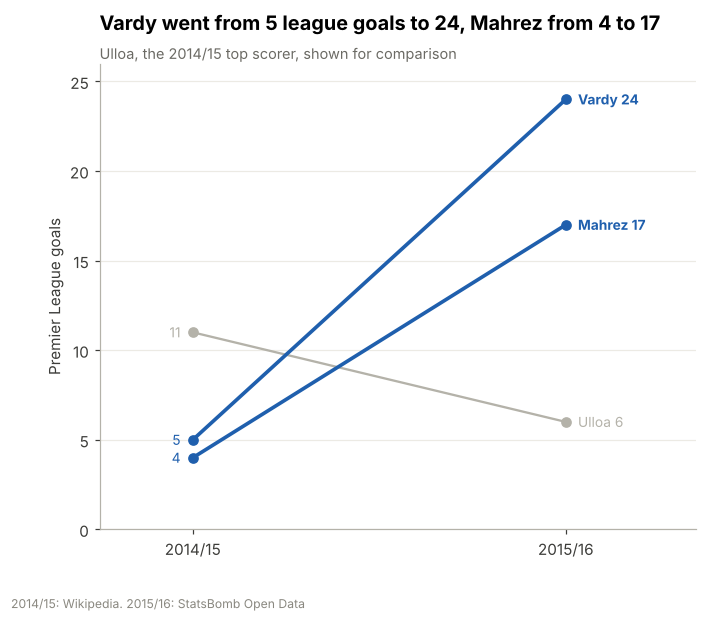

In [11]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for r in prog[prog.player.isin(["Jamie Vardy", "Riyad Mahrez", "Leonardo Ulloa"])].itertuples():
    star = r.player in ["Jamie Vardy", "Riyad Mahrez"]
    c = BLUE if star else GREY
    ax.plot([0, 1], [r.goals_1415, r.goals_1516], color=c, lw=2.4 if star else 1.5, marker="o", ms=6, zorder=3 if star else 2)
    ax.annotate(f"{r.goals_1415}", (0, r.goals_1415), xytext=(-8, 0), textcoords="offset points", ha="right", va="center",
                fontsize=9, color=c)
    ax.annotate(f"{r.player.split()[-1]} {r.goals_1516}", (1, r.goals_1516), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=c, fontweight="bold" if star else "normal")
ax.set_xticks([0, 1], ["2014/15", "2015/16"])
ax.set_xlim(-0.25, 1.35); ax.set_ylim(0, 26)
ax.set_ylabel("Premier League goals")
ax.grid(axis="x", visible=False)
ax.set_title("Vardy went from 5 league goals to 24, Mahrez from 4 to 17", pad=22)
subtitle(ax, "Ulloa, the 2014/15 top scorer, shown for comparison")
source(fig, "2014/15: Wikipedia. 2015/16: StatsBomb Open Data")
fig.savefig(FIGS / "12_goals_2014_15_vs_2015_16.png"); plt.show()

### Bargain core: what the key players cost

Fees from Wikipedia and contemporary reports (sources below).

In [12]:
pd.DataFrame([
    ("Jamie Vardy", "Fleetwood Town, 2012", "£1m (non-league record)", "24 goals, joint 2nd behind Kane (25); Premier League Player of the Season"),
    ("Riyad Mahrez", "Le Havre, 2014", "about £450,000", "17 goals; PFA Players' Player of the Year"),
    ("N'Golo Kanté", "Caen, 2015", "£5.6m", "Most tackles + interceptions in the league; sold to Chelsea for a reported £32m in 2016"),
    ("Christian Fuchs", "Schalke 04, 2015", "Free", "Most blocks in the league"),
    ("Robert Huth", "Stoke City, 2015", "£3m", "35 league starts, 2nd-most clearances"),
    ("Shinji Okazaki", "Mainz 05, 2015", "£7m", "91st-percentile pressing among forwards"),
], columns=["Player", "Signed from", "Fee", "2015/16"])

,Player,Signed from,Fee,2015/16
0,Jamie Vardy,"Fleetwood Town, 2012",£1m (non-league record),"24 goals, joint 2nd behind Kane (25); Premier ..."
1,Riyad Mahrez,"Le Havre, 2014","about £450,000",17 goals; PFA Players' Player of the Year
2,N'Golo Kanté,"Caen, 2015",£5.6m,Most tackles + interceptions in the league; so...
3,Christian Fuchs,"Schalke 04, 2015",Free,Most blocks in the league
4,Robert Huth,"Stoke City, 2015",£3m,"35 league starts, 2nd-most clearances"
5,Shinji Okazaki,"Mainz 05, 2015",£7m,91st-percentile pressing among forwards


## Summary

1. **Money:** Leicester spent about £27m in summer 2015, 12th of 20 clubs. Manchester City spent £154m and finished 4th, 15 points behind. De Bruyne's fee alone (£54.5m) was double Leicester's whole summer.
2. **Signings:** four signings became regulars (Kanté, Huth, Fuchs, Okazaki) for about £15.6m combined. They were bought for specific jobs:
   - Kanté ranked in the 100th percentile of midfielders for tackles, interceptions and ball recoveries per 90.
   - Fuchs was 100th percentile among defenders for blocks and 98th for chances created.
   - Okazaki ranked 91st–92nd percentile among forwards for pressing. Benteke, who cost £32.5m, was 6th.
   - Huth ranked 97th percentile among defenders for clearances.
3. **Not better at everything:** the big-money buys were better at scoring (Benteke) and passing (Schneiderlin, Otamendi). Leicester's signings won on ball-winning and work-rate, which suited a counter-attacking side.
4. **Progression:** the team went from 14th (41 points) to 1st (81). Vardy went from 5 goals to 24, and Mahrez from 4 to 17, with mostly the same squad plus four signings.
5. **The run began earlier:** counting the 2015 escape from relegation, Leicester took 103 points from 47 matches (2.19 per match).

**Limitations:** spending and fees come from secondary sources and some fees are undisclosed. 2014/15 has no event data here, so only appearances and goals can be compared. Percentiles depend on the position grouping, which is based on each player's most-played position.

### Sources

- [2015–16 Leicester City F.C. season, Wikipedia](https://en.wikipedia.org/wiki/2015%E2%80%9316_Leicester_City_F.C._season): signings, fees, pre-season odds
- [2014–15 Leicester City F.C. season, Wikipedia](https://en.wikipedia.org/wiki/2014%E2%80%9315_Leicester_City_F.C._season): 2014/15 table, run-in, player goals
- [Jamie Vardy, Wikipedia](https://en.wikipedia.org/wiki/Jamie_Vardy) and [Riyad Mahrez, Wikipedia](https://en.wikipedia.org/wiki/Riyad_Mahrez): season stats, awards, Mahrez's fee
- [Sky Sports: Foxes agree record Vardy deal (8 June 2012)](https://www.skysports.com/football/news/11712/7762163/Foxes-agree-record-Vardy-deal)
- [Sky Sports: the 10 most expensive deals of the summer 2015 window](https://skysports.com/football/news/11096/9975549/the-10-most-expensive-deals-of-the-summer-transfer-window)
- [Sportskeeda: how much all 20 Premier League clubs spent in summer 2015](https://widgets.sportskeeda.com/football/how-much-all-20-premier-league-clubs-spend-2015-summer-transfer-window)
- [The Scotsman: Leicester's £26m profit on Kanté sale](https://www.scotsman.com/sport/football/leicesters-aps26m-profit-sale-ngolo-kante-chelsea-1472042)